# 🔴 Implement for MA1 (some codes are common)

## ⚪ 1. Libraries

In [3]:
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

## ⚪ 2. Extract indices from .csv file

In [4]:
# Define the path to your CSV file.
csv_file_path = 'mammographyori.csv'

In [5]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    # For better readability, let's assign names to the columns.
    df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']

    # --- Step 2: Apply the condition to define the MA1 subset ---
    condition = (df_original['c4'] >= -0.9) & (df_original['c4'] <= 2)

    # Create the MA1 subset dataframe by applying the filter
    df_ma1 = df_original[condition]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    ma1_indices = df_ma1.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in MA1 ---
    ma1_label_counts = df_ma1['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the MA1 condition: {len(ma1_indices)}")

    # Display the number of outliers in MA1.
    print(f"Number of outliers in the MA1 subset: {ma1_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (11183, 7) (rows, columns)
Number of samples satisfying the MA1 condition: 10951
Number of outliers in the MA1 subset: label
1    10747
2      204
Name: count, dtype: int64


## ⚪ 3. Making X_tem from MA1 indices italicized text

In [6]:
print("Shape of MA1: ", ma1_indices.shape, )
print()
print("index of MA1 :", ma1_indices)
print()
print("type of MA1: ", type(ma1_indices))

Shape of MA1:  (10951,)

index of MA1 : [    0     1     2 ... 11180 11181 11182]

type of MA1:  <class 'numpy.ndarray'>


In [7]:
# Conver ma1_indices to python list
X_tem1 = ma1_indices.tolist()

## ⚪ 4. Checking .mat file

In [8]:
mat = scipy.io.loadmat('mammography.mat')
print(mat.keys())
print(pd.DataFrame(mat['trandata']).describe())

# mat['trandata']

dict_keys(['__header__', '__version__', '__globals__', 'trandata'])
                  0             1             2             3             4  \
count  11183.000000  11183.000000  11183.000000  11183.000000  11183.000000   
mean       0.024291      0.084628      0.019676      0.082248      0.015748   
std        0.030967      0.179984      0.033256      0.095687      0.041675   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.020928      0.013535      0.011994      0.000000      0.000000   
75%        0.034013      0.070860      0.026987      0.160732      0.000000   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

                  5             6  
count  11183.000000  11183.000000  
mean       0.326703      0.023250  
std        0.345453      0.150702  
min        0.000000      0.000000  
25%        0.000000      0.000000  
50% 

## ⚪ 5. Main code of 3WNCROD

In [9]:
def WNCROD(data, X_tem, lammda):

    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


## ⚪ 6. Run algorythm for MA1

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 6 columns
    y1 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X1[:, 1:] = scaler.fit_transform(X1[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores = WNCROD(X1, X_tem1, lammda=0.5)

    # 5) Extract true labels only for X_tem1
    y_true = y1[X_tem1]

    # 6) Compute metrics
    roc_auc1 = roc_auc_score(y_true, out_scores)
    ap1      = average_precision_score(y_true, out_scores)

    print(f"ROC-AUC: {roc_auc1:.4f}")
    print(f"Average Precision (AP): {ap1:.4f}")

ROC-AUC: 0.8931
Average Precision (AP): 0.3550


In [ ]:
if __name__ == "__main__":

    # 0) لیست 10 مقدار λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 6 columns
    y1 = full_data[:, 6].astype(int)        # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X1[:, 1:] = scaler.fit_transform(X1[:, 1:])

    # 4) True labels for MA1 (فرض بر این است که X_tem از قبل تعریف شده)
    y_true = y1[X_tem1]

    # 5) حلقه روی همه λها و محاسبهٔ خروجی و معیارها
    results = []
    for lam in lambda_list:
        out_scores = WNCROD(X1, X_tem1, lammda=lam)

        # (اختیاری) می‌توانید فقط خودِ out_scores را پرینت کنید:
        # print(f"lambda={lam:.1f} → out_scores[:10] = {out_scores[:10]}")

        # محاسبهٔ معیارها
        roc_auc = roc_auc_score(y_true, out_scores)
        ap      = average_precision_score(y_true, out_scores)

        results.append({
            'lambda': lam,
            'ROC-AUC': roc_auc,
            'AP': ap
        })

    # 6) نمایش نتایج
    for r in results:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

In [ ]:
# لیست λها و مقادیر متناظر ROC-AUC
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

roc_auc_list = [0.3409, 0.4595, 0.6006, 0.7606, 0.8931,
                0.8874, 0.8610, 0.8548, 0.8506, 0.8448,
                0.8277, 0.8196, 0.8154, 0.8082, 0.8032,
                0.7934, 0.7858, 0.7787, 0.7761, 0.7727]

# رسم نمودار
plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_list, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (MA1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## ⚪ 7. Radius Neighborhood for MA1

In [ ]:
    n, m = X1.shape
    lammda = 0.5
    delta = np.zeros(m)
    ID = np.all(X1 <= 1, axis=0)
    delta[ID] = np.std(X1[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X1.shape[1]} Features with λ = {lammda} for MA1:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")






"""
    Neighborhood radius for each 6 Features with λ = 0.5 for MA2:
       Feature :  1: δ(Neighborhood radius ) = 0.061930
       Feature :  2: δ(Neighborhood radius ) = 0.359952
       Feature :  3: δ(Neighborhood radius ) = 0.066510
       Feature :  4: δ(Neighborhood radius ) = 0.191366
       Feature :  5: δ(Neighborhood radius ) = 0.083347
       Feature :  6: δ(Neighborhood radius ) = 0.690875
  """

Neighborhood radius for each 6 Features with λ = 0.5 for MA1:
  Feature :  1: δ(Neighborhood radius ) = 0.061930
  Feature :  2: δ(Neighborhood radius ) = 0.359952
  Feature :  3: δ(Neighborhood radius ) = 0.066510
  Feature :  4: δ(Neighborhood radius ) = 0.191366
  Feature :  5: δ(Neighborhood radius ) = 0.083347
  Feature :  6: δ(Neighborhood radius ) = 0.690875


'\nNeighborhood radius for each 6 Features with λ = 0.5 for MA2:\n   Feature :  1: δ(Neighborhood radius ) = 0.061930\n   Feature :  2: δ(Neighborhood radius ) = 0.359952\n   Feature :  3: δ(Neighborhood radius ) = 0.066510\n   Feature :  4: δ(Neighborhood radius ) = 0.191366\n   Feature :  5: δ(Neighborhood radius ) = 0.083347\n   Feature :  6: δ(Neighborhood radius ) = 0.690875\n  '

# 🔴 Implement for MA2

## ⚪ 2. Extract indices from .csv file

In [10]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    # For better readability, let's assign names to the columns.
    df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']

    # --- Step 2: Apply the condition2 to define the MA2 subset ---
    condition2 = (df_original['c5'] >= -0.4) & (df_original['c5'] <= 1)

    # Create the MA2 subset dataframe by applying the filter
    df_ma2 = df_original[condition2]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    ma2_indices = df_ma2.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in MA2 ---
    ma2_label_counts = df_ma2['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the MA2 condition: {len(ma2_indices)}")

    # Display the number of outliers in MA1.
    print(f"Number of outliers in the MA2 subset: {ma2_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (11183, 7) (rows, columns)
Number of samples satisfying the MA2 condition: 10098
Number of outliers in the MA2 subset: label
1    10022
2       76
Name: count, dtype: int64


## ⚪ 3. Making X_tem from MA2 indices italicized text

In [11]:
# Conver ma2_indices to python list
X_tem2 = ma2_indices.tolist()

## ⚪ 6. Run algorythm for MA2

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X2 = full_data[:, :6]                   # First 6 columns
    y2 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X2[:, 1:] = scaler.fit_transform(X2[:, 1:])

    # 4) Run the algorithm with the same X_tem2 and lammda=0.5
    out_scores2 = WNCROD(X2, X_tem2, lammda=0.5)

    # 5) Extract true labels only for X_tem2
    y_true2 = y2[X_tem2]

    # 6) Compute metrics
    roc_auc_MA2 = roc_auc_score(y_true2, out_scores2)
    ap_MA2      = average_precision_score(y_true2, out_scores2)

    print(f"ROC-AUC: {roc_auc_MA2:.4f}")
    print(f"Average Precision (AP): {ap_MA2:.4f}")

In [ ]:
if __name__ == "__main__":
    # لیست λهایی که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 1) بارگذاری داده
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # شکل: (n_samples, 7)

    # 2) جدا کردن ویژگی‌ها و برچسب‌ها
    X2 = full_data[:, :6]                  # 6 ستون اول
    y2 = full_data[:, 6].astype(int)       # ستون 7 (اندیس 6)

    # 3) نرمال‌سازی ویژگی‌ها (ستون‌های 2 تا 6)
    scaler = MinMaxScaler()
    X2[:, 1:] = scaler.fit_transform(X2[:, 1:])

    # تعریف X_tem2 (فهرست اندیس‌های نمونه‌های مرجعِ MA2)
    # مثال: X_tem2 = [0, 2, 5, 10, ...]
    # مطمئن شوید که X_tem2 قبلاً تعریف شده است
    # -----------------------------------------
    # X_tem2 = [...]

    # 4) برچسب‌های واقعی برای نمونه‌های X_tem2
    y_true2 = y2[X_tem2]

    # 5) حلقه برای اجرای WNCROD با مقادیر مختلف λ و محاسبه معیارها
    results2 = []
    for lam in lambda_list:
        out_scores2 = WNCROD(X2, X_tem2, lammda=lam)
        roc2 = roc_auc_score(y_true2, out_scores2)
        ap2  = average_precision_score(y_true2, out_scores2)
        results2.append({
            'lambda': lam,
            'ROC-AUC': roc2,
            'AP': ap2
        })

    # 6) نمایش نتایج
    print("نتایج MA2 برای λهای مختلف:")
    for r in results2:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

## ⚪ 7. Radius Neighborhood for MA2

In [ ]:
    n, m = X2.shape
    lammda = 0.5
    delta = np.zeros(m)
    ID = np.all(X2 <= 1, axis=0)
    delta[ID] = np.std(X2[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X2.shape[1]} Features with λ = {lammda} for MA2:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 6 Features with λ = 0.5 for MA2:
  Feature :  1: δ(Neighborhood radius ) = 0.061930
  Feature :  2: δ(Neighborhood radius ) = 0.359952
  Feature :  3: δ(Neighborhood radius ) = 0.066510
  Feature :  4: δ(Neighborhood radius ) = 0.191366
  Feature :  5: δ(Neighborhood radius ) = 0.083347
  Feature :  6: δ(Neighborhood radius ) = 0.690875


# 🔴 Implement for MA3

## ⚪ 2. Extract indices from .csv file

In [ ]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    # For better readability, let's assign names to the columns.
    df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']

    # --- Step 2: Apply the condition3 to define the MA3 subset ---
    condition3 = (df_original['c6'] >= -1) & (df_original['c6'] <= 1)

    # Create the MA3 subset dataframe by applying the filter
    df_ma3 = df_original[condition3]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    ma3_indices = df_ma3.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in MA3 ---
    ma3_label_counts = df_ma3['label'].value_counts()

    # --- Output and Verification ---
    print(f"MA2 Condition: Feature 'c6' must be in the range [-1, 1].")
    print(f"Total number of samples in the original dataset: {len(df_original)}")
    print(f"Number of samples satisfying the MA3 condition: {len(ma3_indices)}")

    # Display the first few indices for a quick check.
    print(f"First 10 indices of the MA3 subset: {ma3_indices[:10]}")

    # Display the number of outliers in MA1.
    print(f"Number of outliers in the MA3 subset: {ma3_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (11183, 7) (rows, columns)
MA2 Condition: Feature 'c6' must be in the range [-1, 1].
Total number of samples in the original dataset: 11183
Number of samples satisfying the MA3 condition: 8263
First 10 indices of the MA3 subset: [ 0  1  2  3  5  7  9 11 12 13]
Number of outliers in the MA3 subset: label
1    8209
2      54
Name: count, dtype: int64


## ⚪ 3. Making X_tem from MA3 indices italicized text

In [ ]:
# Conver ma3_indices to python list
X_tem3 = ma3_indices.tolist()

## ⚪ 6. Run algorythm for MA3

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X3 = full_data[:, :6]                   # First 6 columns
    y3 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X3[:, 1:] = scaler.fit_transform(X3[:, 1:])

    # 4) Run the algorithm with the same X_tem3 and lammda=0.6
    out_scores3 = WNCROD(X3, X_tem3, lammda=0.6)

    # 5) Extract true labels only for X_tem3
    y_true3 = y3[X_tem3]

    # 6) Compute metrics
    roc_auc_MA3 = roc_auc_score(y_true3, out_scores3)
    ap_MA3      = average_precision_score(y_true3, out_scores3)

    print(f"ROC-AUC: {roc_auc_MA3:.4f}")
    print(f"Average Precision (AP): {ap_MA3:.4f}")

ROC-AUC: 0.7880
Average Precision (AP): 0.1669


In [ ]:

if __name__ == "__main__":
    # 1) مقادیر λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 2) بارگذاری داده
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 3) جدا کردن ویژگی‌ها و برچسب‌ها
    X3 = full_data[:, :6]                  # First 6 columns
    y3 = full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 4) نرمال‌سازی ویژگی‌ها (ستون‌های 2 تا 6)
    scaler = MinMaxScaler()
    X3[:, 1:] = scaler.fit_transform(X3[:, 1:])

    # 5) تعریف X_tem3 (لیست اندیس‌های نمونه‌های MA3)
    # این متغیر باید قبلاً مقداردهی شود، مثال:
    # X_tem3 = [0, 3, 7, 12, ...]
    # ---------------------------------------
    # X_tem3 = [...]

    # 6) استخراج برچسب‌های واقعی برای X_tem3
    y_true3 = y3[X_tem3]

    # 7) اجرای حلقه برای همه λها و محاسبهٔ معیارها
    results3 = []
    for lam in lambda_list:
        out_scores3 = WNCROD(X3, X_tem3, lammda=lam)
        roc3 = roc_auc_score(y_true3, out_scores3)
        ap3  = average_precision_score(y_true3, out_scores3)
        results3.append({
            'lambda': lam,
            'ROC-AUC': roc3,
            'AP': ap3
        })

    # 8) نمایش نتایج
    print("نتایج MA3 برای λهای مختلف:")
    for r in results3:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")



نتایج MA3 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.4075 | AP = 0.0522
λ = 0.2 | ROC-AUC = 0.5280 | AP = 0.0699
λ = 0.3 | ROC-AUC = 0.6631 | AP = 0.1572
λ = 0.4 | ROC-AUC = 0.7750 | AP = 0.1195
λ = 0.5 | ROC-AUC = 0.7748 | AP = 0.0827
λ = 0.6 | ROC-AUC = 0.7880 | AP = 0.1669
λ = 0.7 | ROC-AUC = 0.7610 | AP = 0.1656
λ = 0.8 | ROC-AUC = 0.7126 | AP = 0.1866
λ = 0.9 | ROC-AUC = 0.7093 | AP = 0.1638
λ = 1.0 | ROC-AUC = 0.7127 | AP = 0.0999
λ = 1.1 | ROC-AUC = 0.7052 | AP = 0.0788
λ = 1.2 | ROC-AUC = 0.7065 | AP = 0.0751
λ = 1.3 | ROC-AUC = 0.7036 | AP = 0.0551
λ = 1.4 | ROC-AUC = 0.7200 | AP = 0.0560
λ = 1.5 | ROC-AUC = 0.7175 | AP = 0.0456
λ = 1.6 | ROC-AUC = 0.7213 | AP = 0.0443
λ = 1.7 | ROC-AUC = 0.7292 | AP = 0.0443
λ = 1.8 | ROC-AUC = 0.7346 | AP = 0.0429
λ = 1.9 | ROC-AUC = 0.7351 | AP = 0.0427
λ = 2.0 | ROC-AUC = 0.7351 | AP = 0.0420


# 🟢 Final plot

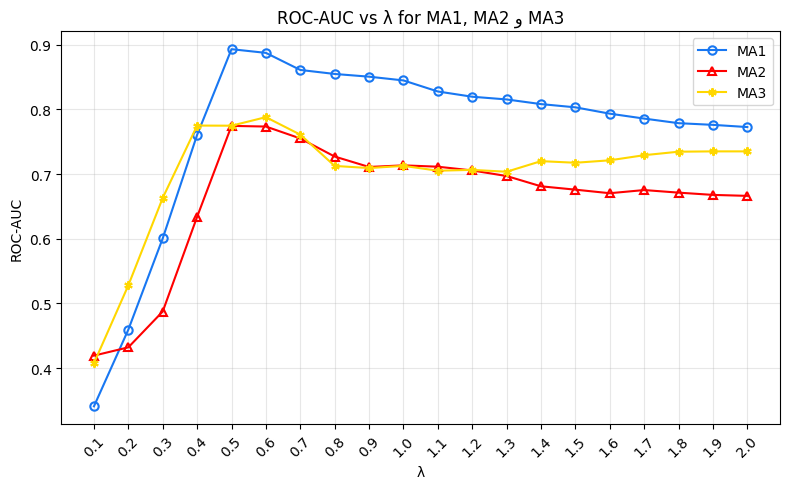

In [ ]:
# بازه مشترک λ برای هر سه MA
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

# مقادیر ROC-AUC برای هر MA
roc_auc_ma1 = [0.3409, 0.4595, 0.6006, 0.7606, 0.8931,
               0.8874, 0.8610, 0.8548, 0.8506, 0.8448,
               0.8277, 0.8196, 0.8154, 0.8082, 0.8032,
               0.7934, 0.7858, 0.7787, 0.7761, 0.7727]


roc_auc_ma2 = [0.4193, 0.4321, 0.4875, 0.6339, 0.7745,
               0.7735, 0.7551, 0.7271, 0.7110, 0.7135,
               0.7114, 0.7056, 0.6970, 0.6811, 0.6759,
               0.6704, 0.6753, 0.6713, 0.6678, 0.6663]

roc_auc_ma3 = [0.4075, 0.5280, 0.6631, 0.7750, 0.7748,
               0.7880, 0.7610, 0.7126, 0.7093, 0.7127,
               0.7052, 0.7065, 0.7036, 0.7200, 0.7175,
               0.7213, 0.7292, 0.7346, 0.7351, 0.7351]

plt.figure(figsize=(8, 5))

# MA1: دایره توخالی
plt.plot(lambda_list, roc_auc_ma1,
         color='#1877F2', linestyle='-',
         marker='o', fillstyle='none',
         markeredgecolor='#1877F2', markeredgewidth=1.5,
         label='MA1')

# MA2: مثلث توخالی
plt.plot(lambda_list, roc_auc_ma2,
         color='red', linestyle='-',
         marker='^', fillstyle='none',
         markeredgecolor='red', markeredgewidth=1.5,
         label='MA2')

# MA3: ستاره 6 پر توخالی (هگزاگرام)
plt.plot(lambda_list, roc_auc_ma3,
         color='gold', linestyle='-',
         marker=(6, 2, 0), fillstyle='none',
         markeredgecolor='gold', markeredgewidth=1.5,
         label='MA3')

plt.title('ROC-AUC vs λ for MA1, MA2 و MA3')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 🔵 New Approach for MA1

### 1. Main code of new 3WNCROD

In [ ]:
def NEW_WNCROD(data: np.ndarray, X_tem: list[int], lammda_list: list[float]) -> np.ndarray:

    n, m = data.shape
    lammda_arr = np.array(lammda_list, dtype=float)
    if lammda_arr.shape[0] != m:
        raise ValueError(f"The length of lammda_list must be equal to the #features : ({m}).")

    X = np.zeros(n, dtype=int)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    # Calculate independent neighborhood radius for each feature
    delta = np.zeros(m, dtype=float)
    ID = np.all(data <= 1, axis=0)
    stds = np.std(data[:, ID], axis=0)
    delta[ID] = stds / lammda_arr[ID]

    Lower = np.zeros((m, n), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    # IB, NEB, NPB
    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    # Weighting
    n_X = int(np.sum(X))
    weight = np.zeros((n_X, m), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        wcol = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            wtemp = 1 - np.sqrt(np.sum(np.minimum(temp1, X)) / n_X)
            wcol.append(wtemp)
        weight[:, col] = wcol

    # D_tem & NOM
    D_tem = np.zeros((n, n), dtype=int)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem.astype(int)
    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    # counting : NEB_num, Lower_num, NPB_num
    NEB_num = np.zeros((n_X, m), dtype=int)
    Lower_num = np.zeros((n_X, m), dtype=int)
    NPB_num = np.zeros((n_X, m), dtype=int)
    for col in range(m):
        tLower = Lower[col, :]
        tNPB   = NPB[col, :]
        for i in range(n_X):
            row_OM = X_OM[i, :]
            NEB_num[i, col]   = np.sum(np.minimum(NEB[X_tem],    row_OM <= D1))
            NPB_num[i, col]   = np.sum(np.minimum(tNPB[X_tem],   row_OM >= D2))
            Lower_num[i, col] = np.sum(np.minimum(tLower[X_tem], row_OM >= D3))

    # calculate MNOF
    NDF = (NEB_num + Lower_num + NPB_num) / n_X
    MNOF = np.mean(NDF * weight, axis=1)
    return MNOF

### 2. runing algo

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.3, 0.05, 0.05, 0.5, 0.7, 0.5]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.8944
Average Precision (AP): 0.5648


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [0.5, 0.1, 0.1, 0.6, 0.7, 0.5]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9191
Average Precision (AP): 0.5074


> 👉👉 **Its ok and it works. we claimed the same result for same lammda.** ✅
>
> **Now we will loking for improvments by searching for best lammda list. 👇👇👇**

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem1]

    # Selecting the criterion function
    if metric_name.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix


=== Best Lambdas for AP ===
[0.3 0.1 0.1 0.5 0.7 0.5]
=== Best Lambdas for ROC-AUC ===
[0.5 0.1 0.1 0.6 0.7 0.5]


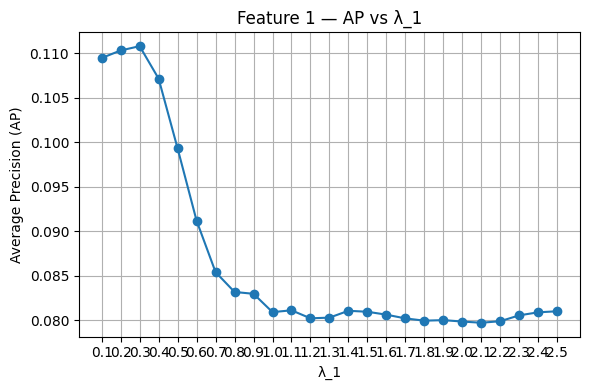

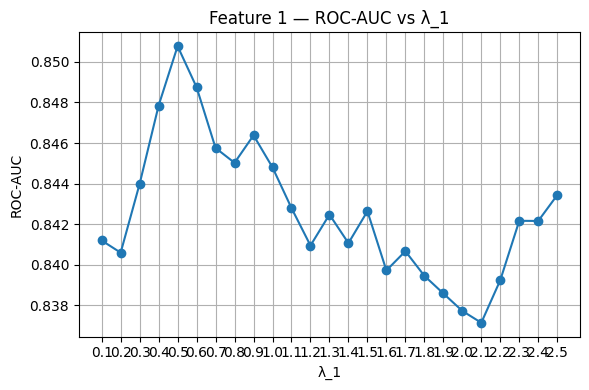

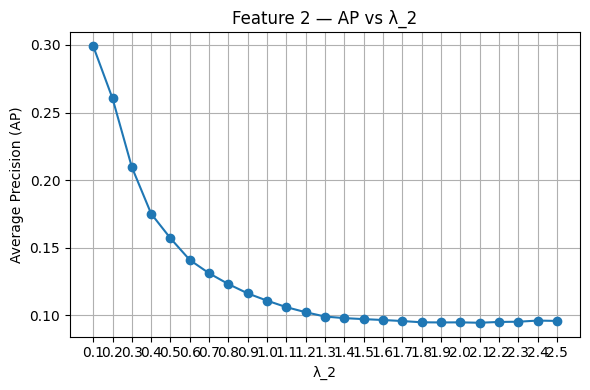

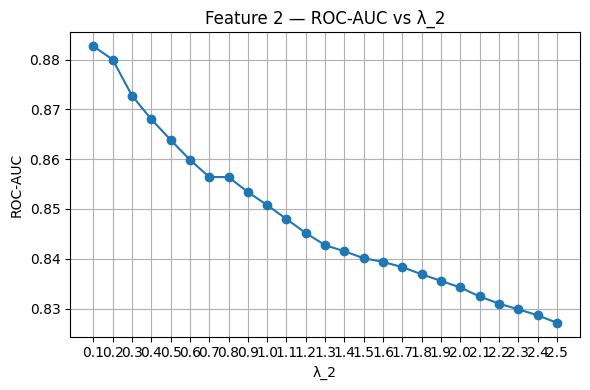

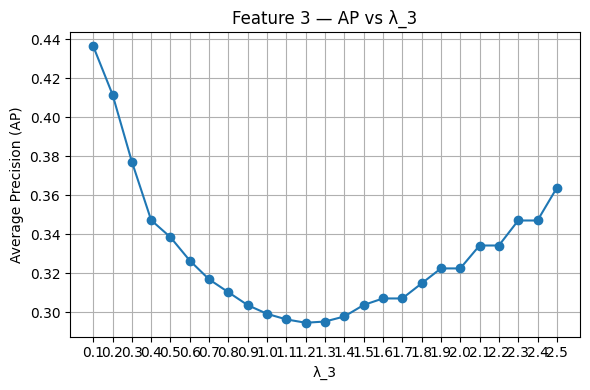

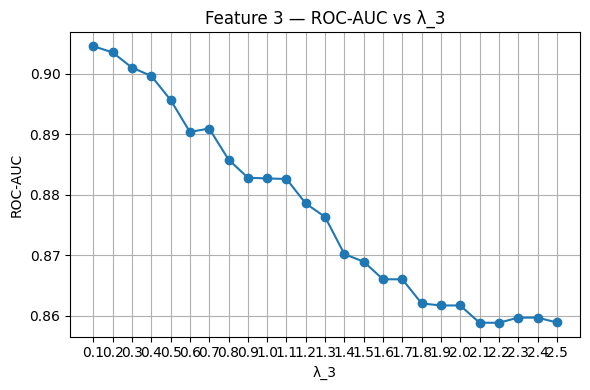

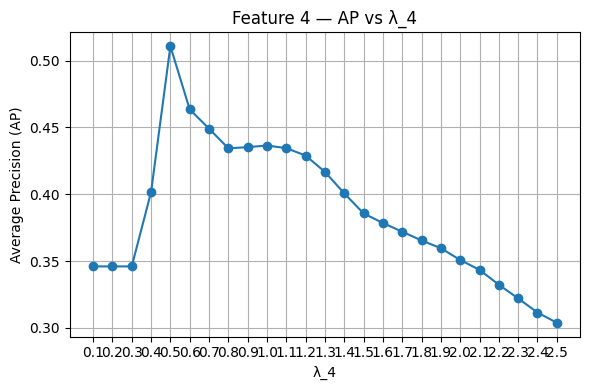

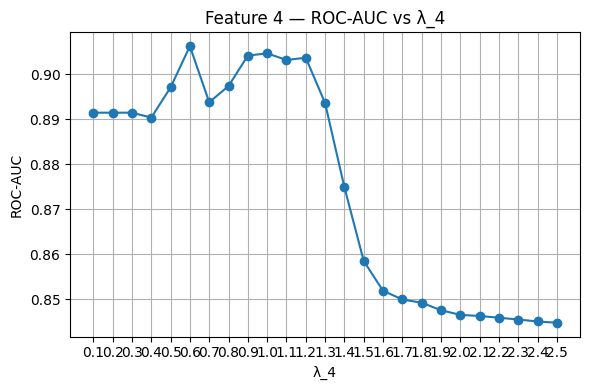

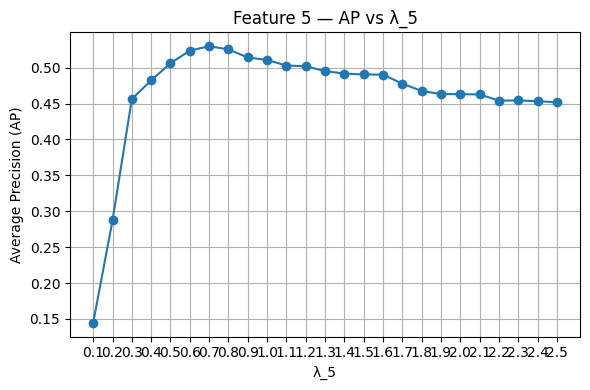

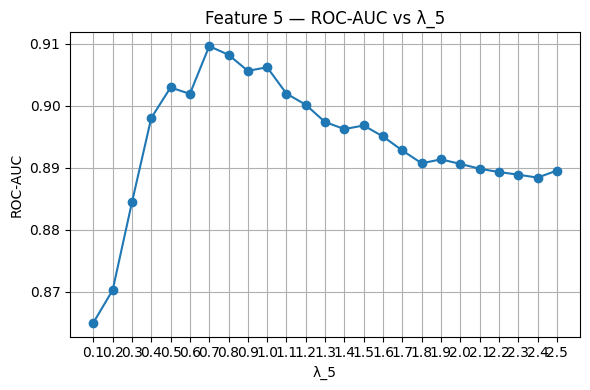

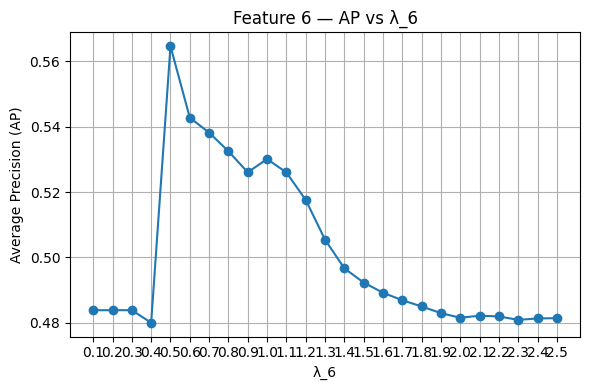

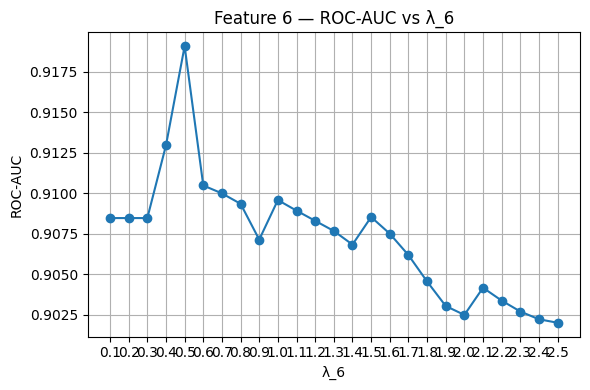

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('mammography.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X11 = full_data[:, :6]
    y11 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # X_tem

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for MA2

### 2. runing algo

In [ ]:
# Conver ma2_indices to python list
X_tem2 = ma2_indices.tolist()

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.4, 2.0, 0.1, 0.4, 1.0, 0.4]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :6]                   # First 6 columns
    y22 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.6565
Average Precision (AP): 0.1220


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [1.3, 0.1, 0.1, 0.6, 0.8, 0.4]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :6]                   # First 6 columns
    y22 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.8322
Average Precision (AP): 0.0939


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas2(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name2: str = 'AP'):

    m = X22.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem2]

    # Selecting the criterion function
    if metric_name2.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name2.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name2 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.4 2.  0.1 0.4 1.  0.4]
=== Best Lambdas for ROC-AUC ===
[1.3 0.1 0.1 0.6 0.8 0.4]


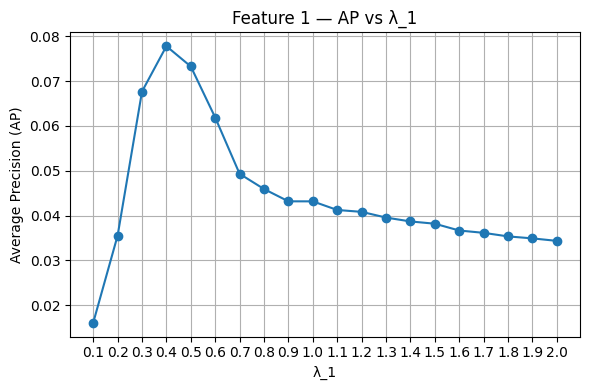

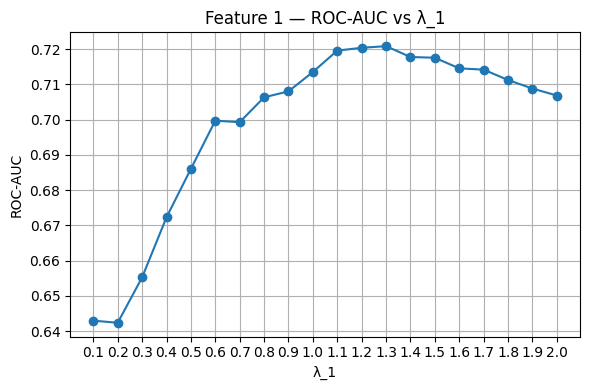

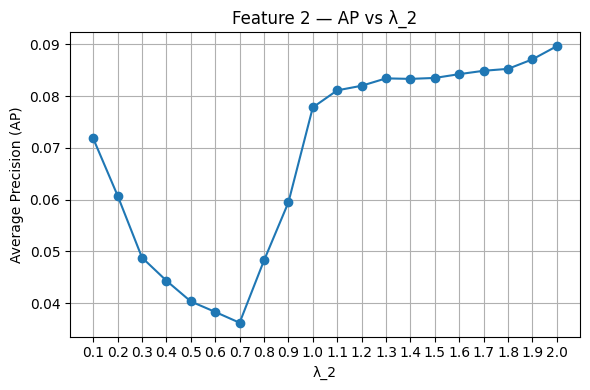

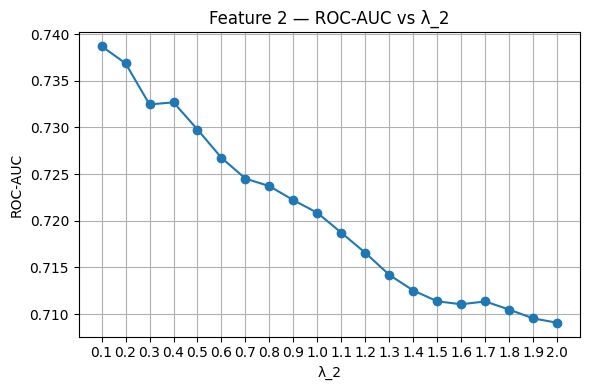

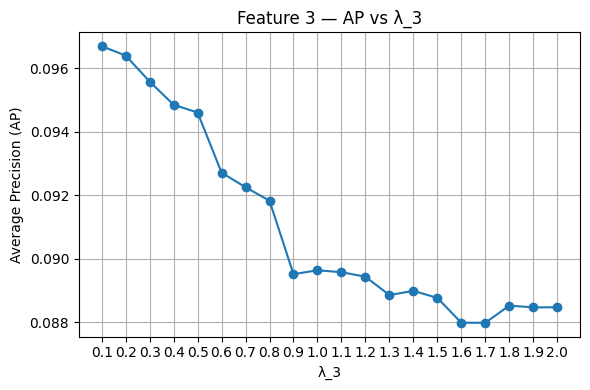

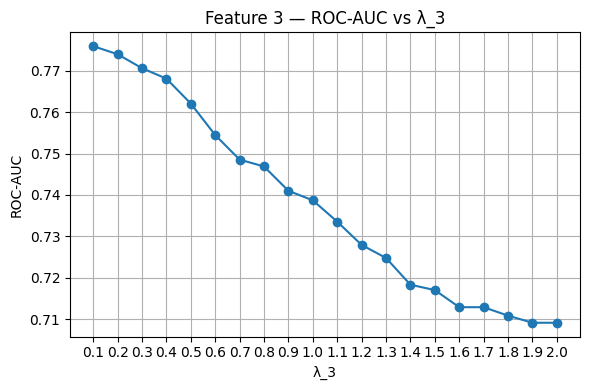

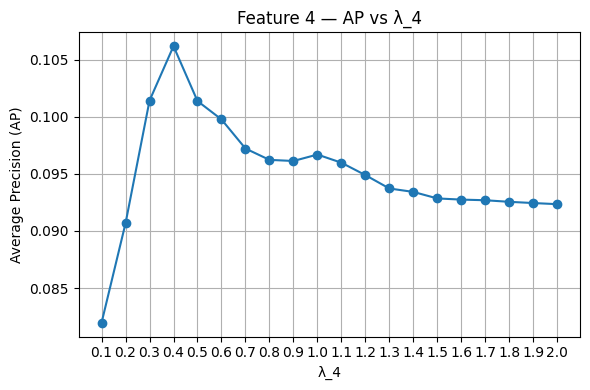

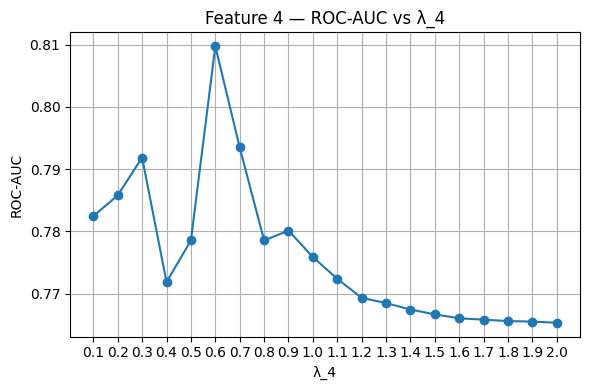

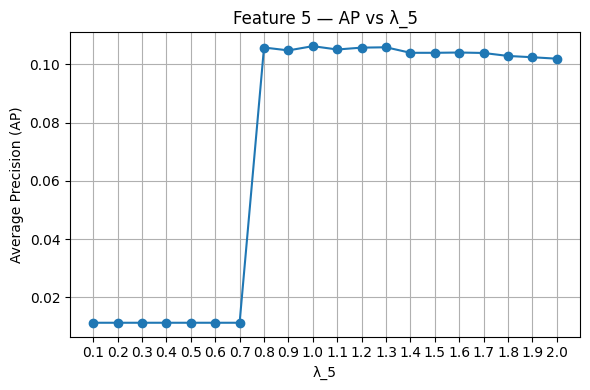

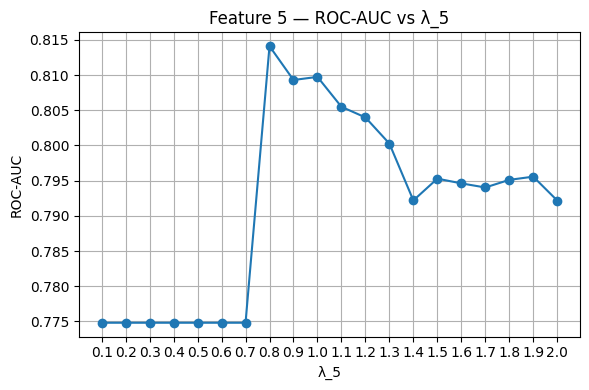

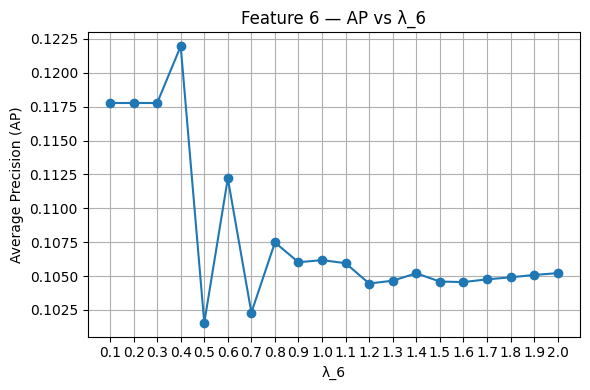

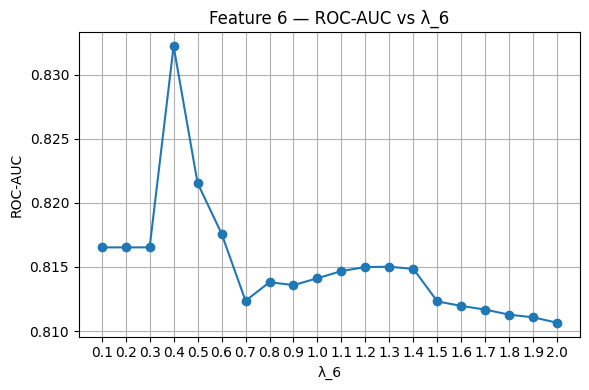

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================

    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================

    mat = loadmat('mammography.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X22 = full_data[:, :6]
    y22 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X22.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for MA3

### 2. runing algo

In [1]:
# Conver ma3_indices to python list
X_tem3 = ma3_indices.tolist()

NameError: name 'ma3_indices' is not defined

In [2]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.5, 2.0, 0.9, 0.4, 0.5, 2.0]

     # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

NameError: name 'loadmat' is not defined

In [ ]:
# this is for best lammda list for TOP ROC
if __name__ == "__main__":

    lammda = [0.5, 1.1, 0.8, 0.4, 0.5, 0.6]

    # 1) Load data
    mat       = loadmat('mammography.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas3(X33: np.ndarray,
                          y33: np.ndarray,
                          X_tem3: list[int],
                          candidates: list[float],
                          metric_name3: str = 'AP'):

    m = X33.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true3 = y33[X_tem3]

    # Selecting the criterion function
    if metric_name3.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name3.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name3 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X33, X_tem3, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true3, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.5 2.  0.9 0.4 0.5 2. ]
=== Best Lambdas for ROC-AUC ===
[0.5 1.1 0.8 0.4 0.5 0.6]


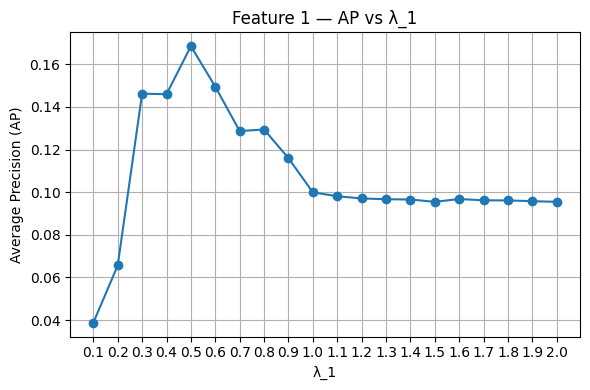

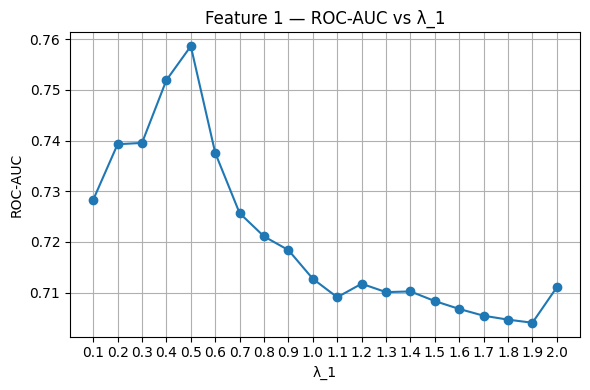

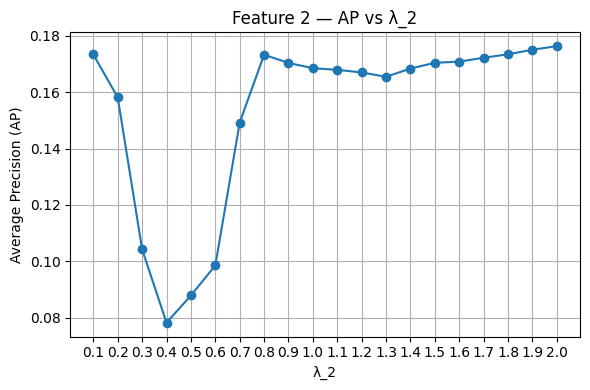

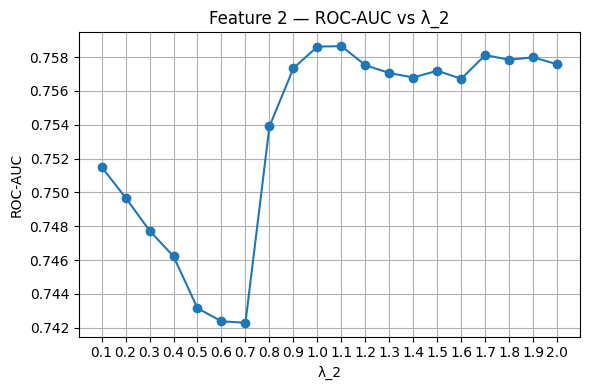

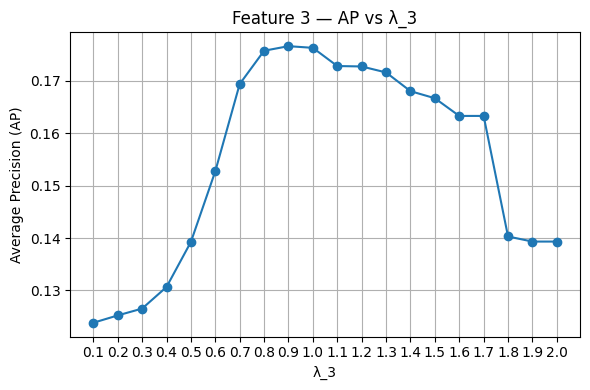

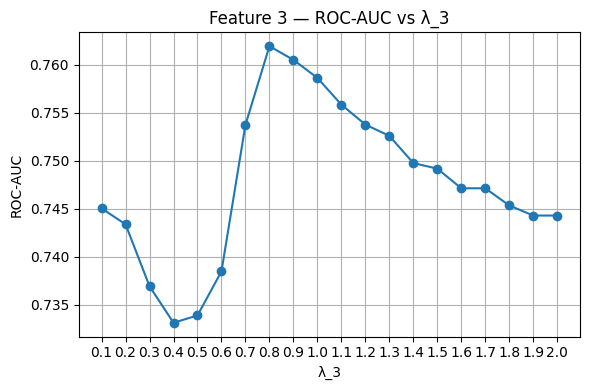

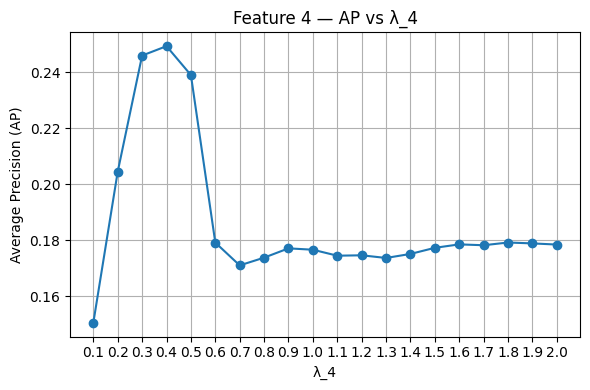

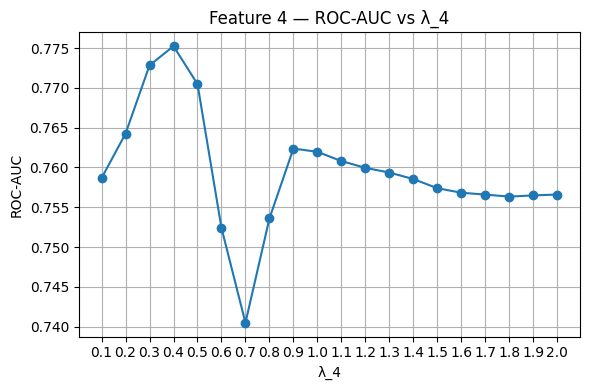

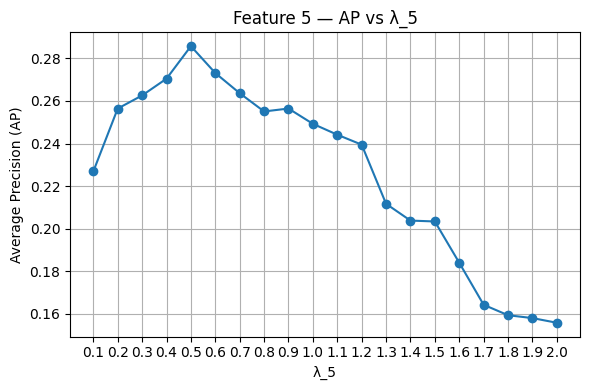

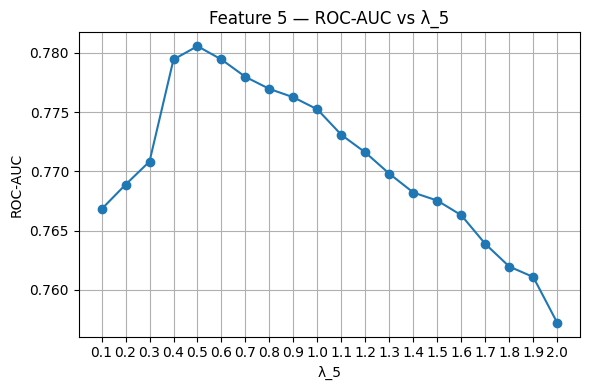

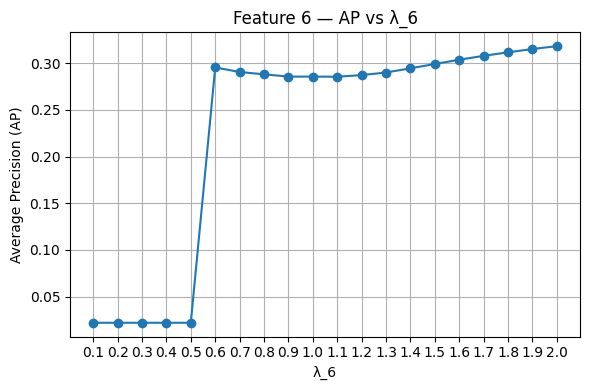

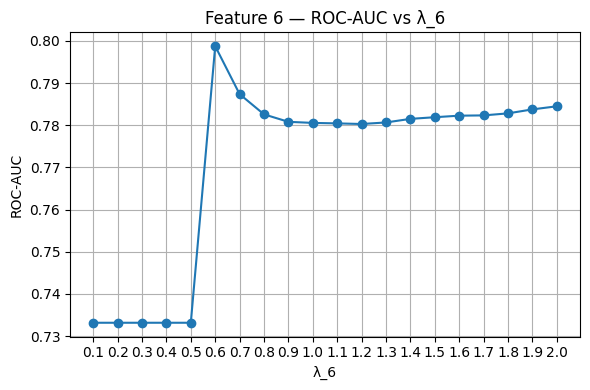

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('mammography.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X33 = full_data[:, :6]
    y33 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # X_tem

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X33.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()